# Práctica obligatoria · Primer modelo de clasificación

**Tiempo estimado:** 40 minutos  
**Recorrido:** SQL + Python

En esta práctica vas a construir un primer modelo de clasificación con el dataset del Titanic. El objetivo no es memorizar código ni estudiar todavía todas las métricas posibles, sino comprender el recorrido básico de un problema supervisado: definir qué queremos predecir, separar entrenamiento y prueba, preparar los datos sin fugas de información, entrenar un árbol de decisión y revisar sus primeras predicciones.

El notebook prepara automáticamente el entorno, descarga el dataset y crea la conexión con DuckDB.


## El problema

Queremos predecir si una persona sobrevivió al naufragio a partir de algunas características disponibles en el dataset.

- **Variable objetivo:** `Survived`.
- **Tipo de problema:** clasificación binaria.
- **Predictores iniciales:** clase del pasaje, sexo, edad, cantidad de hermanos o cónyuges a bordo y tarifa pagada.

> Una asociación aprendida por el modelo no demuestra causalidad. El resultado debe interpretarse dentro del contexto histórico y reconociendo los límites y sesgos del dataset.


In [1]:
#@title Preparación automática del entorno
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

for package in ["duckdb", "pandas", "scikit-learn", "matplotlib"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
DATA_PATH = Path("titanic.csv")
if not DATA_PATH.exists():
    urlretrieve(DATA_URL, DATA_PATH)

titanic_original = pd.read_csv(DATA_PATH)
columnas_necesarias = {"survived", "pclass", "sex", "age", "sibsp", "fare"}
if not columnas_necesarias.issubset(titanic_original.columns):
    raise ValueError("El archivo Titanic no contiene las columnas esperadas.")
if "con" in globals():
    con.close()
con = duckdb.connect(":memory:")
con.register("titanic_original", titanic_original)
con.execute("CREATE OR REPLACE TABLE titanic AS SELECT * FROM titanic_original")

print(f"Entorno preparado: {len(titanic_original):,} pasajeros y {titanic_original.shape[1]} variables.")


Entorno preparado: 891 pasajeros y 15 variables.


## Selección inicial de variables con SQL


In [2]:
df = con.sql("""
SELECT
    survived AS Survived,
    pclass AS Pclass,
    sex AS Sex,
    age AS Age,
    sibsp AS SibSp,
    fare AS Fare
FROM titanic
""").df()

print(f"Pasajeros seleccionados: {len(df):,}")
df.head(10)


Pasajeros seleccionados: 891


,Survived,Pclass,Sex,Age,SibSp,Fare
0,0,3,male,22.0,1,7.2500
1,1,1,female,38.0,1,71.2833
2,1,3,female,26.0,0,7.9250
3,1,1,female,35.0,1,53.1000
4,0,3,male,35.0,0,8.0500
5,0,3,male,NaN,0,8.4583
6,0,1,male,54.0,0,51.8625
7,0,3,male,2.0,3,21.0750
8,1,3,female,27.0,0,11.1333
9,1,2,female,14.0,1,30.0708


## Entrenamiento y prueba: separar antes de preparar

El modelo debe aprender con los datos de **entrenamiento**. Reservamos los datos de **prueba** para observar cómo responde ante personas que no utilizó para aprender.

**Importante:** primero separamos los conjuntos y **después** vamos a calcular la mediana para completar las edades faltantes. Si utilizáramos la mediana del dataset completo, la preparación aprovecharía información del conjunto de prueba. Esto se denomina **fuga de información (*data leakage*)**.


In [3]:
from sklearn.model_selection import train_test_split

# Separar primero evita que la información del conjunto de prueba
# influya en decisiones tomadas durante la preparación.
y = df["Survived"]
X = df.drop(columns=["Survived"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

print(f"Entrenamiento: {len(X_train):,} pasajeros")
print(f"Prueba: {len(X_test):,} pasajeros")
print("Edades faltantes en entrenamiento:", X_train["Age"].isna().sum())
print("Edades faltantes en prueba:", X_test["Age"].isna().sum())


Entrenamiento: 623 pasajeros
Prueba: 268 pasajeros
Edades faltantes en entrenamiento: 119
Edades faltantes en prueba: 58


## Preparación de los datos sin fuga de información

Revisamos los valores faltantes en ambos conjuntos. Para esta práctica completamos las edades ausentes utilizando la mediana calculada únicamente con los datos de entrenamiento. Aplicamos exactamente ese mismo valor a entrenamiento y a prueba.

También representamos `Sex` con dos categorías equivalentes en ambos conjuntos, de una manera que el árbol pueda procesar. Esta simplificación tiene fines didácticos; en un proyecto real tendríamos que justificar la preparación de las variables y considerar otras alternativas.


In [4]:
# El valor para completar edades faltantes se aprende SOLO con entrenamiento.
mediana_edad = X_train["Age"].median()
X_train["Age"] = X_train["Age"].fillna(mediana_edad)
X_test["Age"] = X_test["Age"].fillna(mediana_edad)

# Codificación binaria explícita de Sex en los dos conjuntos.
# Usamos la misma regla fija: female = 0, male = 1.
codificacion_sexo = {"female": 0, "male": 1}
X_train["Sex"] = X_train["Sex"].map(codificacion_sexo)
X_test["Sex"] = X_test["Sex"].map(codificacion_sexo)

if X_train.isna().any().any() or X_test.isna().any().any():
    raise ValueError("Quedaron valores faltantes o categorías no reconocidas. Revisá el dataset.")

print(f"Mediana calculada solo con entrenamiento: {mediana_edad:.1f}")
print("Valores faltantes restantes en entrenamiento:", X_train.isna().sum().sum())
print("Valores faltantes restantes en prueba:", X_test.isna().sum().sum())
print("Predictores:", list(X_train.columns))


Mediana calculada solo con entrenamiento: 29.0
Valores faltantes restantes en entrenamiento: 0
Valores faltantes restantes en prueba: 0
Predictores: ['Pclass', 'Sex', 'Age', 'SibSp', 'Fare']


## Primer árbol de decisión

Un árbol de decisión aprende reglas sucesivas para separar las clases. Limitaremos su profundidad para obtener un modelo pequeño y legible. Un árbol más grande podría ajustarse demasiado a los datos de entrenamiento.


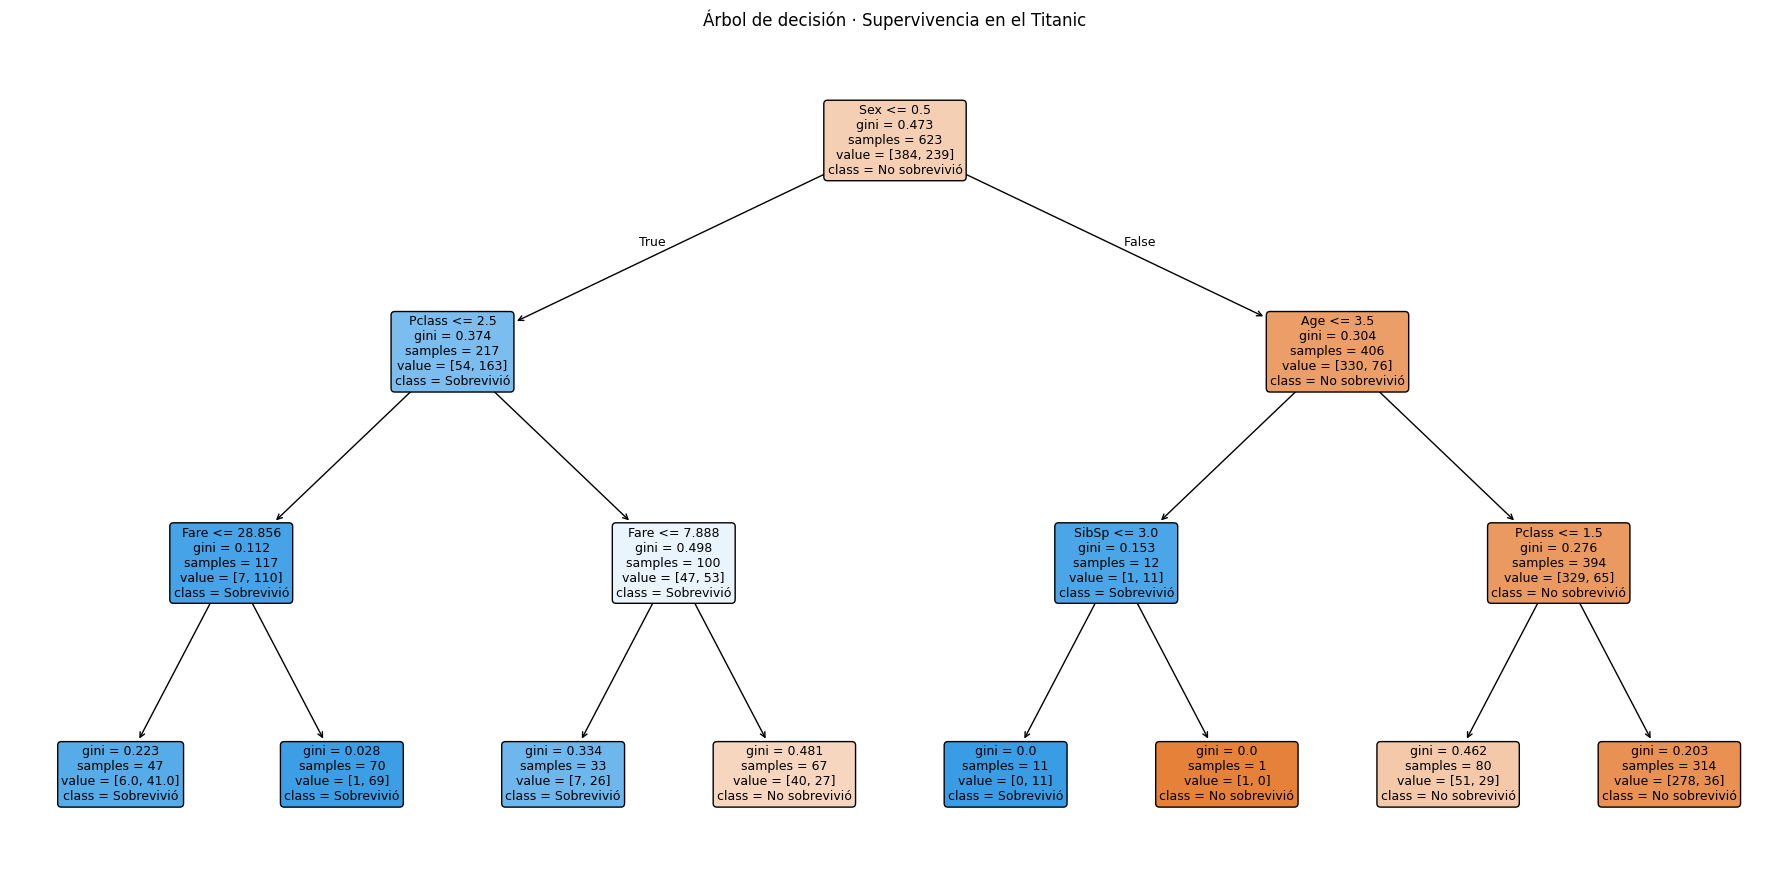

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    modelo,
    feature_names=X_train.columns,
    class_names=["No sobrevivió", "Sobrevivió"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
ax.set_title("Árbol de decisión · Supervivencia en el Titanic")
plt.tight_layout()
plt.show()


## Primeras predicciones

En esta semana utilizaremos la proporción de aciertos solamente como una primera aproximación. Más adelante estudiaremos por qué una única medida no alcanza para evaluar un modelo y trabajaremos con métricas específicas.


In [6]:
from sklearn.metrics import accuracy_score

y_pred = modelo.predict(X_test)
resultados = X_test.copy()
resultados["Sobrevivio_real"] = y_test.values
resultados["Sobrevivio_predicho"] = y_pred
resultados["Acierto"] = resultados["Sobrevivio_real"] == resultados["Sobrevivio_predicho"]

display(resultados.head(12))
accuracy = accuracy_score(y_test, y_pred)
print(f"Proporción de aciertos en prueba: {accuracy:.2%}")


,Pclass,Sex,Age,SibSp,Fare,Sobrevivio_real,Sobrevivio_predicho,Acierto
625,1,1,61.0,0,32.3208,0,0,True
566,3,1,19.0,0,7.8958,0,0,True
459,3,1,29.0,0,7.7500,0,0,True
804,3,1,27.0,0,6.9750,1,0,False
338,3,1,45.0,0,8.0500,1,0,False
745,1,1,70.0,1,71.0000,0,0,True
277,2,1,29.0,0,0.0000,0,0,True
473,2,0,23.0,0,13.7917,1,1,True
157,3,1,30.0,0,8.0500,0,0,True
427,2,0,19.0,0,26.0000,1,1,True


Proporción de aciertos en prueba: 79.48%


## ¿Qué variables utilizó el modelo?

La importancia indica cuánto contribuyó cada variable a las divisiones realizadas por el árbol. No significa que esas variables causen la supervivencia ni autoriza, por sí sola, una decisión sobre personas.


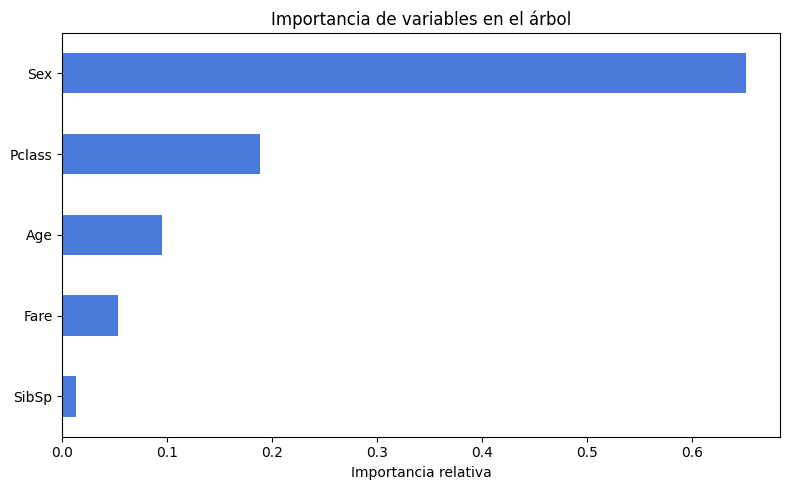

In [7]:
importancias = pd.Series(modelo.feature_importances_, index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importancias.plot(kind="barh", color="#4a7bdc", ax=ax)
ax.set_title("Importancia de variables en el árbol")
ax.set_xlabel("Importancia relativa")
plt.tight_layout()
plt.show()


## Preguntas para orientar la interpretación

Respondé en el notebook:

1. ¿Cuál es la pregunta predictiva que intenta responder el modelo?
2. ¿Por qué corresponde a un problema de clasificación?
3. ¿Por qué separamos entrenamiento y prueba **antes** de calcular la mediana de las edades faltantes?
4. ¿Qué variable aparece como más importante en este árbol?
5. ¿Por qué esa importancia no demuestra una relación causal?
6. ¿Qué limitaciones habría que considerar antes de utilizar un modelo semejante para tomar decisiones reales?

## A modo de cierre

Al finalizar deberías poder explicar el recorrido inicial de un problema de clasificación: definir el objetivo, seleccionar predictores, separar entrenamiento y prueba, preparar los datos sin fugas de información, entrenar un modelo y revisar críticamente sus resultados.


In [8]:
if "con" in globals():
    con.close()